In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [ ]:
data = pd.read_csv('/content/diabetes.csv')

In [ ]:
data

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
df = pd.DataFrame(data)

In [ ]:
df


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
le={}
df_enc=df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])
df_enc

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,86,22,28,0,123,350,29,1
1,1,23,19,22,0,62,196,10,0
2,8,121,17,0,0,30,368,11,1
3,1,27,19,16,62,77,53,0,0
4,0,75,4,28,102,209,514,12,1
...,...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42,0
764,2,60,21,20,0,155,187,6,0
765,5,59,22,16,71,58,115,9,0
766,1,64,14,0,0,95,195,26,1


In [ ]:
X = df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df_enc['Outcome']
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,86,22,28,0,123,350,29
1,1,23,19,22,0,62,196,10
2,8,121,17,0,0,30,368,11
3,1,27,19,16,62,77,53,0
4,0,75,4,28,102,209,514,12
...,...,...,...,...,...,...,...,...
763,10,39,25,41,108,118,55,42
764,2,60,21,20,0,155,187,6
765,5,59,22,16,71,58,115,9
766,1,64,14,0,0,95,195,26


In [ ]:
y

,Outcome
0,1
1,0
2,1
3,0
4,1
...,...
763,0
764,0
765,0
766,1


In [ ]:
model = CategoricalNB()
model.fit(X, y)

CategoricalNB()

In [ ]:
test = [
    [6, 148, 72, 35, 0, 33.6, 0.627, 50],
]

In [ ]:
test

[[6, 148, 72, 35, 0, 33.6, 0.627, 50]]

In [ ]:
print('\n--- Prediction ------------------------------------->')
for t in test:
    encoded_row = [[
        le['Pregnancies'].transform([t[0]])[0],
        le['Glucose'].transform([t[1]])[0],
        le['BloodPressure'].transform([t[2]])[0],
        le['SkinThickness'].transform([t[3]])[0],
        le['Insulin'].transform([t[4]])[0],
        le['BMI'].transform([t[5]])[0],
        le['DiabetesPedigreeFunction'].transform([t[6]])[0],
        le['Age'].transform([t[7]])[0]
    ]]

    pred_enc = model.predict(encoded_row)[0]

    prediction = le['Outcome'].inverse_transform([pred_enc])[0]

    print(f"Input features: {t} => Predicted Outcome: {prediction}")


--- Prediction ------------------------------------->
Input features: [6, 148, 72, 35, 0, 33.6, 0.627, 50] => Predicted Outcome: 1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


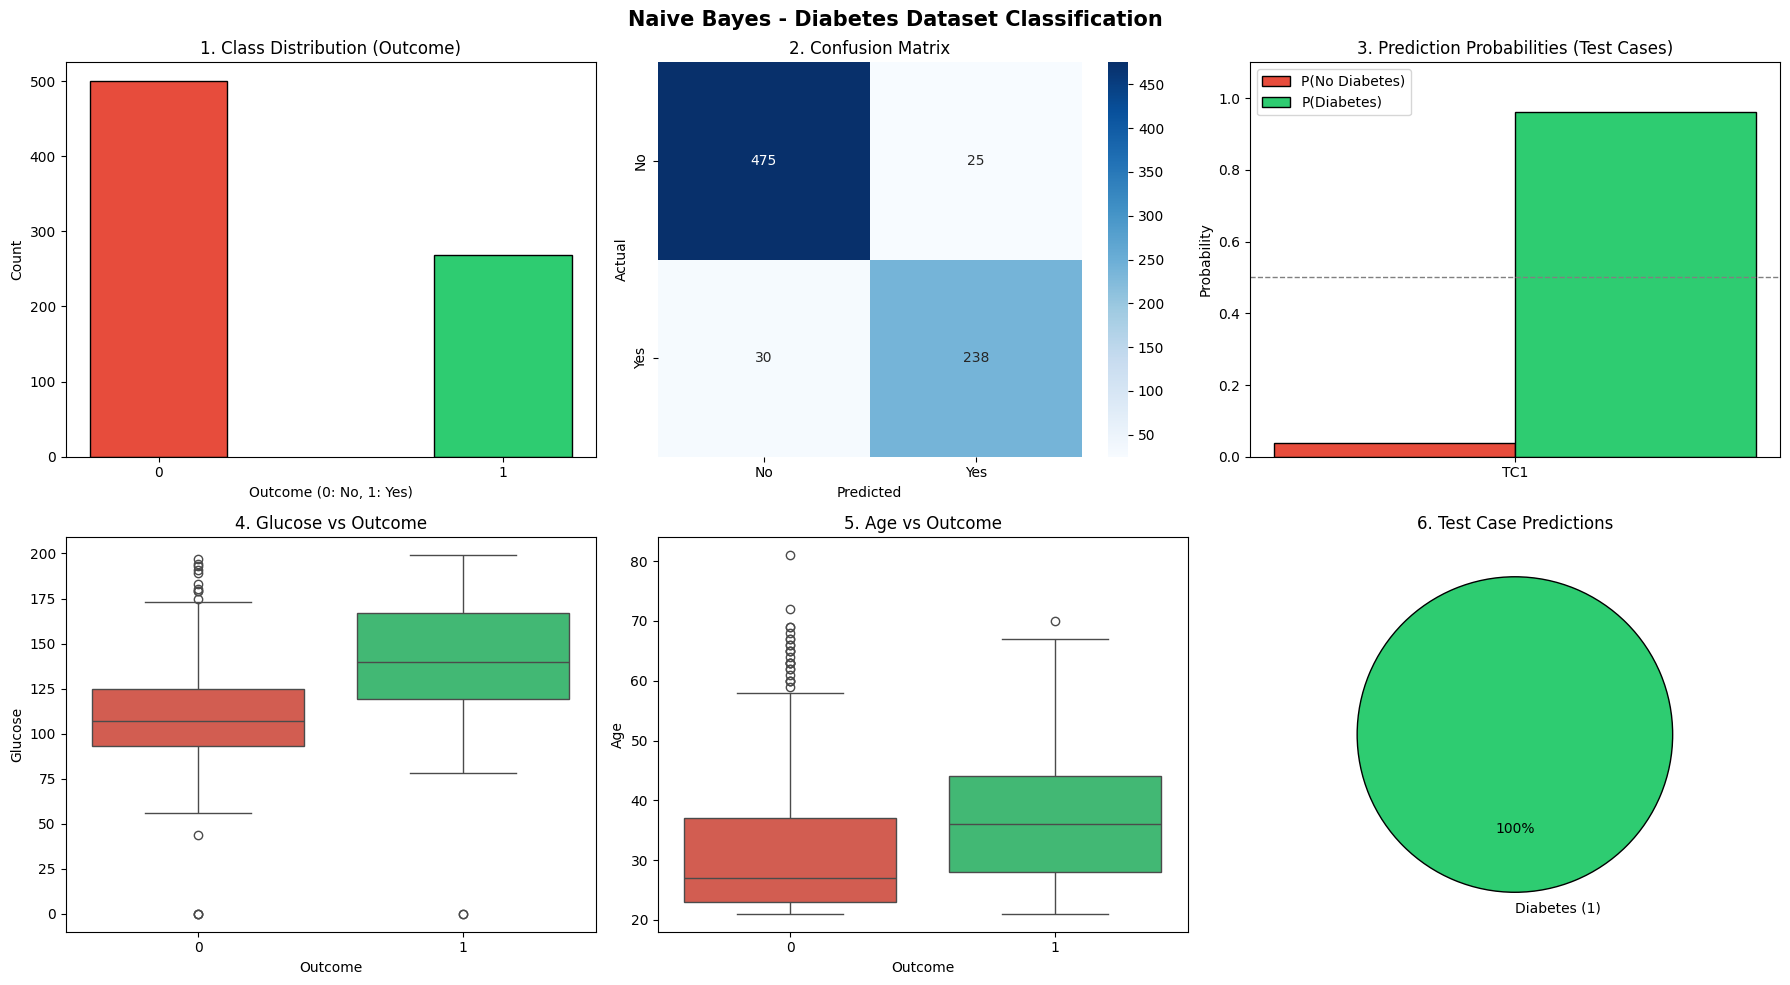

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

# 1. Rebuild and prepare data dependencies (Downloading public copy of the Pima Indians Diabetes Dataset)
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
df = pd.read_csv(url, names=columns)

le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

X = df_enc[['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y = df_enc['Outcome']

# 2. Re-fit the classifier
model = CategoricalNB()
model.fit(X, y)

# 3. Define test cases
test = [
    [6, 148, 72, 35, 0, 33.6, 0.627, 50],
]

# Prepare prediction probabilities and predictions list for the test cases
probs_no = []
probs_yes = []
predictions = []
for t in test:
    row = [[
        le['Pregnancies'].transform([t[0]])[0],
        le['Glucose'].transform([t[1]])[0],
        le['BloodPressure'].transform([t[2]])[0],
        le['SkinThickness'].transform([t[3]])[0],
        le['Insulin'].transform([t[4]])[0],
        le['BMI'].transform([t[5]])[0],
        le['DiabetesPedigreeFunction'].transform([t[6]])[0],
        le['Age'].transform([t[7]])[0]
    ]]
    prob = model.predict_proba(row)[0]
    probs_no.append(prob[0])
    probs_yes.append(prob[1])

    # Generate predicted class name
    pred_class = le['Outcome'].inverse_transform(model.predict(row))[0]
    predictions.append(pred_class)

# Correct grid to 2 rows and 3 columns to host all plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    "Naive Bayes - Diabetes Dataset Classification", fontsize=15, fontweight="bold"
)

# 1. Class Distribution
counts = df["Outcome"].value_counts()
axes[0, 0].bar(
    counts.index.astype(str),
    counts.values,
    color=["#e74c3c", "#2ecc71"],
    edgecolor="black",
    width=0.4,
)
axes[0, 0].set_title("1. Class Distribution (Outcome)")
axes[0, 0].set_xlabel("Outcome (0: No, 1: Yes)")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(X))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'], ax=axes[0, 1])
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test))]
x_coords = np.arange(len(tc_labels))
w = 0.35
axes[0, 2].bar(x_coords - w/2, probs_no, w, label='P(No Diabetes)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_coords + w/2, probs_yes, w, label='P(Diabetes)', color='#2ecc71', edgecolor='black')
axes[0, 2].axhline(0.5, color='gray', linestyle='--', linewidth=1)
axes[0, 2].set_title("3. Prediction Probabilities (Test Cases)")
axes[0, 2].set_xticks(x_coords)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].legend()

# 4. Glucose Distribution vs Outcome
sns.boxplot(data=df, x='Outcome', y='Glucose', ax=axes[1, 0], palette=['#e74c3c', '#2ecc71'], hue='Outcome', legend=False)
axes[1, 0].set_title("4. Glucose vs Outcome")
axes[1, 0].set_xlabel("Outcome")
axes[1, 0].set_ylabel("Glucose")

# 5. Age Distribution vs Outcome
sns.boxplot(data=df, x='Outcome', y='Age', ax=axes[1, 1], palette=['#e74c3c', '#2ecc71'], hue='Outcome', legend=False)
axes[1, 1].set_title("5. Age vs Outcome")
axes[1, 1].set_xlabel("Outcome")
axes[1, 1].set_ylabel("Age")

# 6. Test Case Predictions (Pie Chart)
pred_counts = pd.Series(predictions).value_counts()
colors_pie = ['#2ecc71' if label == 1 else '#e74c3c' for label in pred_counts.index]

axes[1, 2].pie(
    pred_counts.values,
    labels=[f"Diabetes ({l})" if l == 1 else f"No Diabetes ({l})" for l in pred_counts.index],
    autopct="%1.0f%%",
    colors=colors_pie,
    startangle=90,
    wedgeprops={'edgecolor': 'black'}
)
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()

In [6]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X)
print(f"\ntraning Accuracy: {accuracy_score(y, y_pred)*100:.2f}%")


traning Accuracy: 92.84%
